<a href="https://colab.research.google.com/github/CGUILLEN23/ADS-504-EV-Adoption-Project/blob/main/KnnProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score


In [ ]:
df = pd.read_csv("/content/global_ev_adoption_behavior_2026.csv")
df.head()

,age,annual_income,education_level,city_type,daily_commute_km,weekly_travel_distance_km,current_vehicle_type,vehicle_age_years,fuel_expense_per_month,charging_station_accessibility,nearest_charging_station_km,home_charging_available,electricity_cost_per_kwh,environmental_awareness_score,government_incentive_awareness,technology_affinity_score,range_anxiety_score,battery_replacement_concern,ev_knowledge_score,previous_ev_experience,ev_adoption_likelihood,monthly_energy_consumption_kwh,monthly_charging_cost
0,56,23019.0,High School,Suburban,39.8,205.7,Hatchback,6.1,317.1,3.9,9.5,1,0.14,8.3,6.4,5.2,4.6,3.5,6.9,0,High,199.8,28.5
1,46,26440.0,High School,Suburban,34.6,218.4,Sedan,4.4,290.0,4.5,11.6,1,0.16,7.8,10.0,5.7,5.5,7.4,6.9,1,High,139.8,22.9
2,46,57167.0,PhD,Suburban,30.5,177.7,Sedan,0.4,201.4,6.3,6.4,1,0.24,7.6,6.4,7.8,5.3,6.2,6.8,0,High,158.0,38.5
3,23,15841.0,Master,Suburban,44.6,325.9,SUV,0.0,407.3,5.2,8.8,0,0.22,6.2,5.6,5.1,7.9,5.7,7.2,0,Low,207.0,45.0
4,50,51571.0,Master,Urban,52.4,281.0,SUV,5.2,458.4,4.3,0.5,0,0.22,9.7,9.9,8.2,2.6,4.7,8.1,0,High,195.6,43.9


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             50000 non-null  int64  
 1   annual_income                   50000 non-null  float64
 2   education_level                 49500 non-null  object 
 3   city_type                       50000 non-null  object 
 4   daily_commute_km                50000 non-null  float64
 5   weekly_travel_distance_km       50000 non-null  float64
 6   current_vehicle_type            50000 non-null  object 
 7   vehicle_age_years               50000 non-null  float64
 8   fuel_expense_per_month          50000 non-null  float64
 9   charging_station_accessibility  49500 non-null  float64
 10  nearest_charging_station_km     50000 non-null  float64
 11  home_charging_available         50000 non-null  int64  
 12  electricity_cost_per_kwh        

In [ ]:
# Encode categorical text features to numeric integers
label_encoders = {}
for col in df.select_dtypes(include=['object']).columns:
    # Skip processing your target column here if it is an object
    if col != 'ev_adoption_likelihood':
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

In [ ]:
X = df.drop(columns=['ev_adoption_likelihood'])
y = df['ev_adoption_likelihood']

In [ ]:
# 4. Split into a training set (80%) and a testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Scale features (mandatory step for distance-based models like KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
from sklearn.impute import SimpleImputer
import numpy as np

# Impute missing values in X_train_scaled and X_test_scaled
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
X_train_scaled = imputer.fit_transform(X_train_scaled)
X_test_scaled = imputer.transform(X_test_scaled)

# 6. Initialize and fit the K-NN Classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

# 7. Make predictions on the test data
y_pred = knn.predict(X_test_scaled)

# 8. View performance metrics
print(f"Test Set Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Test Set Accuracy: 0.7925

Classification Report:

              precision    recall  f1-score   support

        High       0.87      0.93      0.90      5934
         Low       0.76      0.67      0.71      1650
      Medium       0.59      0.54      0.56      2416

    accuracy                           0.79     10000
   macro avg       0.74      0.71      0.73     10000
weighted avg       0.78      0.79      0.79     10000



In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

k_values = [3, 5, 7, 9, 11, 15, 20, 25]
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

for k, score in zip(k_values, cv_scores):
    print(f"k={k}: CV Accuracy = {score:.4f}")

best_k = k_values[cv_scores.index(max(cv_scores))]
print(f"Best k value: {best_k}")


k=3: CV Accuracy = 0.7886
k=5: CV Accuracy = 0.7969
k=7: CV Accuracy = 0.8095
k=9: CV Accuracy = 0.8144
k=11: CV Accuracy = 0.8196
k=15: CV Accuracy = 0.8256
k=20: CV Accuracy = 0.8306
k=25: CV Accuracy = 0.8316
Best k value: 25


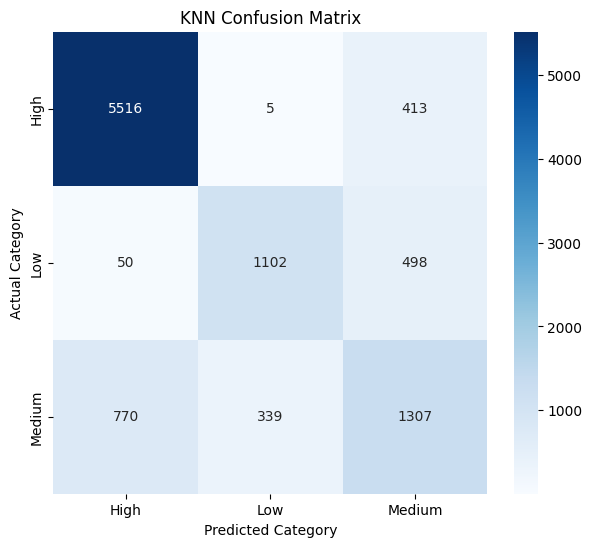

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix array
cm = confusion_matrix(y_test, y_pred)

# Define the class labels based on the presumed encoding (0: High, 1: Low, 2: Medium)
class_labels = ['High', 'Low', 'Medium']

# Plot using Seaborn's heatmap
plt.figure(figsize=(7, 6)) # Adjusted figure size for better readability
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels)

plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.title('KNN Confusion Matrix')
plt.show()

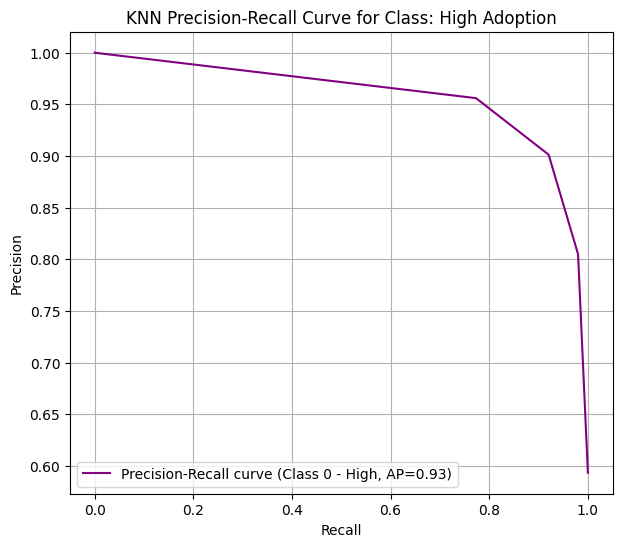

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Get probability estimates for all classes
y_proba = knn.predict_proba(X_test_scaled)

# For multi-class, plot one Precision-Recall curve per class (e.g., for 'High' adoption, which is class 0)
# Binarize the true labels for class 0
y_test_binarized_class_0 = (y_test == 0).astype(int)

# Get the probability estimates for class 0
y_probs_class_0 = y_proba[:, 0]

# Calculate precision and recall for class 0
precision_class_0, recall_class_0, _ = precision_recall_curve(y_test_binarized_class_0, y_probs_class_0)

# Calculate Average Precision Score for class 0
avg_precision_class_0 = average_precision_score(y_test_binarized_class_0, y_probs_class_0)

plt.figure(figsize=(7, 6))
plt.plot(recall_class_0, precision_class_0, color='purple', label=f'Precision-Recall curve (Class 0 - High, AP={avg_precision_class_0:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('KNN Precision-Recall Curve for Class: High Adoption')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# You can extend this to plot for other classes (1 and 2) similarly